In [45]:
# Jika belum menginstal library, jalankan:
# !pip install kagglehub pandas numpy matplotlib seaborn scipy statsmodels scikit-learn

import os
import glob
import re
import warnings

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy import stats
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import (
    het_breuschpagan,
    linear_reset
)
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

sns.set_theme(style="whitegrid")

print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


In [47]:
# Download dataset dari Kaggle
path = kagglehub.dataset_download(
    "joebeachcapital/top-500-hollywood-movies-of-all-time"
)

print("Lokasi dataset:", path)

# Mencari seluruh file CSV
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

print("\nFile CSV yang ditemukan:")
for i, file in enumerate(csv_files):
    print(f"{i}: {os.path.basename(file)}")

Lokasi dataset: C:\Users\ACER\.cache\kagglehub\datasets\joebeachcapital\top-500-hollywood-movies-of-all-time\versions\1

File CSV yang ditemukan:
0: Most Profitable Movies of All Time - Top 500 Movies.csv


In [48]:
# Membaca file CSV pertama
data_raw = pd.read_csv(csv_files[0])

print("Ukuran dataset:", data_raw.shape)
display(data_raw.head())

Ukuran dataset: (562, 16)


,title,worldwide gross (m),% budget recovered,X times budget recovered,budget (millions),domestic gross (m),domestic %,international gross (m),% of gross from international,worldwide gross,year,decade,source,budget source,force label,horror
0,300,456.0000,702%,7.0000,65.0000,211.0000,46.2%,245.0000,53.8%,456082343,2007,2000's,https://www.boxofficemojo.com/chart/ww_top_lif...,NaN,NaN,not horror
1,1917,385.0000,427%,4.3000,90.0000,159.0000,41.4%,225.0000,58.6%,384576334,2019,2010's,https://www.boxofficemojo.com/chart/ww_top_lif...,https://www.nytimes.com/2020/01/12/movies/1917...,NaN,not horror
2,2012,791.0000,396%,4.0000,200.0000,166.0000,21.0%,625.0000,79.0%,791217826,2009,2000's,https://www.boxofficemojo.com/chart/ww_top_lif...,NaN,NaN,not horror
3,101 Dalmatians,321.0000,479%,4.8000,67.0000,136.0000,42.5%,185.0000,57.5%,320689294,1996,1990's,https://www.boxofficemojo.com/chart/ww_top_lif...,https://en.wikipedia.org/wiki/101_Dalmatians_(...,NaN,not horror
4,22 Jump Street,331.0000,663%,6.6000,50.0000,192.0000,57.9%,140.0000,42.1%,331333876,2014,2010's,https://www.boxofficemojo.com/chart/ww_top_lif...,NaN,NaN,not horror


In [49]:
print("Nama kolom:")
print(data_raw.columns.tolist())

print("\nInformasi dataset:")
data_raw.info()

print("\nJumlah missing value:")
display(data_raw.isnull().sum().to_frame("Missing Values"))

Nama kolom:
['title ', 'worldwide gross (m)', '% budget recovered', 'X times budget recovered', 'budget  (millions)', 'domestic gross (m)', 'domestic %', 'international gross (m)', '% of gross from international', 'worldwide gross', 'year', 'decade', 'source', 'budget source', 'force label', 'horror']

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 562 entries, 0 to 561
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   title                          562 non-null    str    
 1   worldwide gross (m)            562 non-null    float64
 2   % budget recovered             562 non-null    str    
 3   X times budget recovered       562 non-null    float64
 4   budget  (millions)             562 non-null    float64
 5   domestic gross (m)             562 non-null    float64
 6   domestic %                     562 non-null    str    
 7   international gross (m)        562 non

,Missing Values
title,0
worldwide gross (m),0
% budget recovered,0
X times budget recovered,0
budget (millions),0
domestic gross (m),0
domestic %,0
international gross (m),0
% of gross from international,0
worldwide gross,0


In [51]:
def normalize_column(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


normalized_columns = {
    normalize_column(col): col
    for col in data_raw.columns
}


def find_column(candidates):
    for candidate in candidates:
        key = normalize_column(candidate)

        if key in normalized_columns:
            return normalized_columns[key]

    return None


# Deteksi nama kolom
budget_col = find_column([
    "budget  (millions)"
])

genre_col = find_column([
    "horror"
])

year_col = find_column([
    "year"
])

gross_col = find_column([
    "worldwide gross (m)"
])


print("Budget        :", budget_col)
print("Genre         :", genre_col)
print("Year          :", year_col)
print("Worldwide Gross:", gross_col)

Budget        : budget  (millions)
Genre         : horror
Year          : year
Worldwide Gross: worldwide gross (m)


In [52]:
data = data_raw[
    [budget_col, genre_col, year_col, gross_col]
].copy()

data.columns = [
    "Budget",
    "Genre",
    "Year",
    "Worldwide_Gross"
]

display(data.head())

,Budget,Genre,Year,Worldwide_Gross
0,65.0000,not horror,2007,456.0000
1,90.0000,not horror,2019,385.0000
2,200.0000,not horror,2009,791.0000
3,67.0000,not horror,1996,321.0000
4,50.0000,not horror,2014,331.0000


In [53]:
def clean_money(series):
    cleaned = (
        series.astype("string")
        .str.replace(",", "", regex=False)
        .str.replace("$", "", regex=False)
        .str.replace("£", "", regex=False)
        .str.replace("€", "", regex=False)
        .str.replace(r"[^\d.\-]", "", regex=True)
    )

    return pd.to_numeric(cleaned, errors="coerce")


data["Budget"] = clean_money(data["Budget"])
data["Worldwide_Gross"] = clean_money(data["Worldwide_Gross"])

In [54]:
# Mengambil empat digit tahun dari kolom Year
data["Year"] = pd.to_numeric(
    data["Year"].astype("string").str.extract(r"(\d{4})")[0],
    errors="coerce"
)

In [57]:
data["Genre"] = (
    data["Genre"]
    .astype("string")
    .str.strip()
    .str.lower()
)

In [59]:
data["Genre"] = data["Genre"].astype("string").str.strip()

# Melihat beberapa kategori genre
print(data["Genre"].value_counts().head(20))

Genre
not horror    513
horror         49
Name: count, dtype: Int64


In [60]:
jumlah_awal = len(data)

data = data.dropna(
    subset=["Budget", "Genre", "Year", "Worldwide_Gross"]
).copy()

# Menghilangkan nilai yang tidak masuk akal untuk analisis ini
data = data[
    (data["Budget"] > 0) &
    (data["Worldwide_Gross"] > 0) &
    (data["Year"] >= 1973) &
    (data["Year"] <= 2023)
].copy()

data = data.drop_duplicates().reset_index(drop=True)

print("Jumlah observasi awal :", jumlah_awal)
print("Jumlah observasi akhir:", len(data))
print("Jumlah data terhapus  :", jumlah_awal - len(data))

display(data.head())

Jumlah observasi awal : 562
Jumlah observasi akhir: 562
Jumlah data terhapus  : 0


,Budget,Genre,Year,Worldwide_Gross
0,65.0000,not horror,2007,456.0000
1,90.0000,not horror,2019,385.0000
2,200.0000,not horror,2009,791.0000
3,67.0000,not horror,1996,321.0000
4,50.0000,not horror,2014,331.0000


In [61]:
print("Tahun minimum:", int(data["Year"].min()))
print("Tahun maksimum:", int(data["Year"].max()))

print("\nJumlah film berdasarkan tahun:")
display(data["Year"].value_counts().sort_index())

Tahun minimum: 1973
Tahun maksimum: 2023

Jumlah film berdasarkan tahun:


Year
1973     1
1975     1
1977     1
1978     1
1980     1
1981     1
1982     1
1983     1
1984     2
1985     1
1986     2
1987     1
1988     2
1989     3
1990     4
1991     3
1992     5
1993     4
1994     6
1995     7
1996     7
1997     6
1998     6
1999    11
2000     8
2001    13
2002    11
2003     9
2004    13
2005    12
2006    12
2007    19
2008    22
2009    23
2010    25
2011    21
2012    32
2013    30
2014    35
2015    34
2016    34
2017    35
2018    35
2019    31
2020     3
2021    11
2022    12
2023     4
Name: count, dtype: Int64

In [62]:
data["Dummy_Horror"] = (
    data["Genre"]
    .str.contains(r"\bHorror\b", case=False, na=False)
    .astype(int)
)

print("Distribusi Dummy Horror:")
display(
    data["Dummy_Horror"]
    .value_counts()
    .rename(index={0: "Non-Horror", 1: "Horror"})
    .to_frame("Jumlah Film")
)

Distribusi Dummy Horror:


,Jumlah Film
Dummy_Horror,
Horror,562


In [63]:
data["Decade"] = (
    (data["Year"] // 10) * 10
).astype(int).astype(str) + "s"

print("Distribusi film berdasarkan dekade:")
display(
    data["Decade"]
    .value_counts()
    .sort_index()
    .to_frame("Jumlah Film")
)

Distribusi film berdasarkan dekade:


,Jumlah Film
Decade,
1970s,4
1980s,15
1990s,59
2000s,142
2010s,312
2020s,30


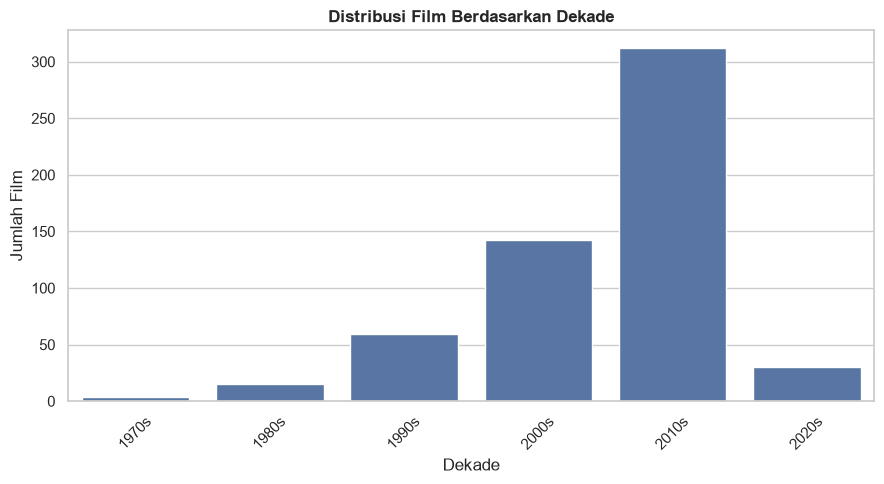

In [64]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=data,
    x="Decade",
    order=sorted(data["Decade"].unique())
)

plt.title("Distribusi Film Berdasarkan Dekade")
plt.xlabel("Dekade")
plt.ylabel("Jumlah Film")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [65]:
assert "1970s" in data["Decade"].unique(), (
    "Kategori 1970s tidak ditemukan. Periksa kembali rentang tahun dan data."
)

In [66]:
display(
    data[
        ["Budget", "Worldwide_Gross", "Year"]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Budget,562.0000,108.4606,76.0276,0.0150,43.2500,100.0000,165.0000,379.0000
Worldwide_Gross,562.0000,532.8840,357.6897,4.0000,342.0000,432.0000,667.7500,"2,923.0000"
Year,562.0000,"2,009.6637",8.9354,"1,973.0000","2,005.0000","2,012.0000","2,016.0000","2,023.0000"


In [67]:
display(
    data.groupby("Dummy_Horror")[
        ["Budget", "Worldwide_Gross"]
    ].agg(["count", "mean", "median", "std"])
)

Budget                           Worldwide_Gross           \
              count     mean   median     std           count     mean   
Dummy_Horror                                                             
1               562 108.4606 100.0000 76.0276             562 532.8840   

                                
               median      std  
Dummy_Horror                    
1            432.0000 357.6897